In [1]:
!rm -rf Car-Parts-Segmentation

!git clone https://github.com/dsmlr/Car-Parts-Segmentation.git

print("Root directory contents:")
!ls

print("\nProject directory contents:")
!ls Car-Parts-Segmentation


Cloning into 'Car-Parts-Segmentation'...
remote: Enumerating objects: 564, done.
remote: Counting objects: 100% (564/564), done.
remote: Compressing objects: 100% (549/549), done.
remote: Total 564 (delta 27), reused 548 (delta 13), pack-reused 0 (from 0)
Receiving objects: 100% (564/564), 24.04 MiB | 47.34 MiB/s, done.
Resolving deltas: 100% (27/27), done.
Root directory contents:
Car-Parts-Segmentation	sample_data

Project directory contents:
doc_images  Example.ipynb  README.md  testset  trainingset


In [2]:
!apt-get -qq install tree

!tree Car-Parts-Segmentation -L 3

Selecting previously unselected package tree.
(Reading database ... 121689 files and directories currently installed.)
Preparing to unpack .../tree_2.0.2-1_amd64.deb ...
Unpacking tree (2.0.2-1) ...
Setting up tree (2.0.2-1) ...
Processing triggers for man-db (2.10.2-1) ...
Car-Parts-Segmentation
├── doc_images
│   ├── instance_per_cats_v2.png
│   ├── instance_per_cats.webp
│   └── samples.webp
├── Example.ipynb
├── README.md
├── testset
│   ├── annotations.json
│   └── JPEGImages
│       ├── car10.jpg
│       ├── car118.jpg
│       ├── car122.jpg
│       ├── car125.jpg
│       ├── car142.jpg
│       ├── car25.jpg
│       ├── car32.jpg
│       ├── car35.jpg
│       ├── car42.jpg
│       ├── car4.jpg
│       ├── car50.jpg
│       ├── car5.jpg
│       ├── car6.jpg
│       ├── car72.jpg
│       ├── car76.jpg
│       ├── car77.jpg
│       ├── car87.jpg
│       ├── car88.jpg
│       ├── te10.jpg
│       ├── te11.jpg
│       ├── te12.jpg
│       ├── te13.jpg
│       ├── te14.jpg
│       ├── 

In [3]:
from pathlib import Path

PROJECT_ROOT = Path("/content/Car-Parts-Segmentation")

TRAIN_IMG_DIR = PROJECT_ROOT / "trainingset" / "JPEGImages"
TEST_IMG_DIR  = PROJECT_ROOT / "testset" / "JPEGImages"

TRAIN_ANN = PROJECT_ROOT / "trainingset" / "annotations.json"
TEST_ANN  = PROJECT_ROOT / "testset" / "annotations.json"

print("Train images dir exists:", TRAIN_IMG_DIR.exists())
print("Test images dir exists :", TEST_IMG_DIR.exists())
print("Train ann exists       :", TRAIN_ANN.exists())
print("Test ann exists        :", TEST_ANN.exists())

Train images dir exists: True
Test images dir exists : True
Train ann exists       : True
Test ann exists        : True


In [4]:
!pip install -q ultralytics opencv-python matplotlib tqdm


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 26.1 MB/s eta 0:00:00


In [5]:
import json
import os
from tqdm import tqdm
import shutil


In [6]:
def load_coco(json_path):
    with open(json_path, "r") as f:
        return json.load(f)


In [7]:
train_coco = load_coco(TRAIN_ANN)
test_coco  = load_coco(TEST_ANN)

print("Train images:", len(train_coco["images"]))
print("Train annotations:", len(train_coco["annotations"]))
print("Categories:", len(train_coco["categories"]))


Train images: 400
Train annotations: 3073
Categories: 19


In [8]:
def coco_to_yolo_bbox(bbox, img_w, img_h):
    x, y, w, h = bbox
    x_center = (x + w / 2) / img_w
    y_center = (y + h / 2) / img_h
    return [x_center, y_center, w / img_w, h / img_h]


In [9]:
YOLO_ROOT = Path("/content/yolo_car_parts")

for split in ["train", "val"]:
    (YOLO_ROOT / split / "images").mkdir(parents=True, exist_ok=True)
    (YOLO_ROOT / split / "labels").mkdir(parents=True, exist_ok=True)


In [10]:
def prepare_yolo_data(coco_data, img_dir, split):
    img_id_map = {img["id"]: img for img in coco_data["images"]}

    label_files = {}

    for ann in coco_data["annotations"]:
        img = img_id_map[ann["image_id"]]
        img_name = img["file_name"]
        img_w, img_h = img["width"], img["height"]

        yolo_box = coco_to_yolo_bbox(ann["bbox"], img_w, img_h)
        class_id = ann["category_id"] - 1  # YOLO is 0-indexed

        label_files.setdefault(img_name, [])
        label_files[img_name].append(
            f"{class_id} " + " ".join(map(str, yolo_box))
        )

    for img_name, labels in tqdm(label_files.items()):
        shutil.copy(
            img_dir / img_name,
            YOLO_ROOT / split / "images" / img_name
        )

        label_path = YOLO_ROOT / split / "labels" / img_name.replace(".jpg", ".txt")
        with open(label_path, "w") as f:
            f.write("\n".join(labels))


In [11]:
prepare_yolo_data(train_coco, TRAIN_IMG_DIR, "train")
prepare_yolo_data(test_coco, TEST_IMG_DIR, "val")


100%|██████████| 100/100 [00:00<00:00, 4712.75it/s]


In [12]:
class_names = [c["name"] for c in train_coco["categories"]]

yaml_content = f"""
path: {YOLO_ROOT}
train: train/images
val: val/images

nc: {len(class_names)}
names: {class_names}
"""

with open("car_parts.yaml", "w") as f:
    f.write(yaml_content)

print(yaml_content)



path: /content/yolo_car_parts
train: train/images
val: val/images

nc: 19
names: ['_background_', 'back_bumper', 'back_glass', 'back_left_door', 'back_left_light', 'back_right_door', 'back_right_light', 'front_bumper', 'front_glass', 'front_left_door', 'front_left_light', 'front_right_door', 'front_right_light', 'hood', 'left_mirror', 'right_mirror', 'tailgate', 'trunk', 'wheel']



In [13]:
from ultralytics import YOLO

model = YOLO("yolo11n.pt")

model.train(
    data="car_parts.yaml",
    epochs=30,
    imgsz=640,
    batch=16,
    device="cpu",
    project="car_parts_runs",
    name="final_exp"
)


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Ultralytics 8.3.241 🚀 Python-3.12.12 torch-2.9.0+cu126 CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=car_parts.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7b35f25fe930>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    

In [14]:
metrics = model.val()

print("mAP@50      :", metrics.box.map50)
print("mAP@50-95   :", metrics.box.map)


Ultralytics 8.3.241 🚀 Python-3.12.12 torch-2.9.0+cu126 CPU (Intel Xeon CPU @ 2.20GHz)
YOLO11n summary (fused): 100 layers, 2,585,857 parameters, 0 gradients, 6.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 971.1±707.9 MB/s, size: 27.5 KB)
val: Scanning /content/yolo_car_parts/val/labels.cache... 100 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 100/100 210.3Kit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 2.5s/it 17.3s
                   all        100        811      0.574      0.779      0.642      0.502
           back_bumper         18         18      0.722          1      0.995      0.815
            back_glass         20         20      0.539       0.85      0.843      0.655
        back_left_door         31         31      0.407      0.677      0.515      0.424
       back_left_light         20         20      0.466        0.9      0.523      0.392
       back_right_door         29      

In [15]:
metrics = model.val()

print("mAP@50      :", metrics.box.map50)
print("mAP@50-95   :", metrics.box.map)

Ultralytics 8.3.241 🚀 Python-3.12.12 torch-2.9.0+cu126 CPU (Intel Xeon CPU @ 2.20GHz)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 968.6±561.5 MB/s, size: 48.6 KB)
val: Scanning /content/yolo_car_parts/val/labels.cache... 100 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 100/100 221.6Kit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 2.4s/it 16.6s
                   all        100        811      0.574      0.779      0.642      0.502
           back_bumper         18         18      0.722          1      0.995      0.815
            back_glass         20         20      0.539       0.85      0.843      0.655
        back_left_door         31         31      0.407      0.677      0.515      0.424
       back_left_light         20         20      0.466        0.9      0.523      0.392
       back_right_door         29         29      0.495      0.724      0.484      0.349
      back_right_light         20


0: 640x640 1 back_left_door, 1 front_bumper, 1 front_glass, 1 front_left_light, 1 front_right_light, 1 hood, 2 wheels, 236.7ms
1: 640x640 1 back_bumper, 1 back_glass, 1 back_left_door, 1 back_left_light, 2 back_right_lights, 1 left_mirror, 1 right_mirror, 1 tailgate, 1 trunk, 236.7ms
Speed: 4.9ms preprocess, 236.7ms inference, 4.4ms postprocess per image at shape (1, 3, 640, 640)


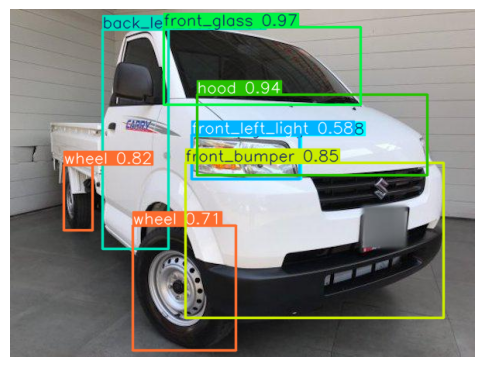

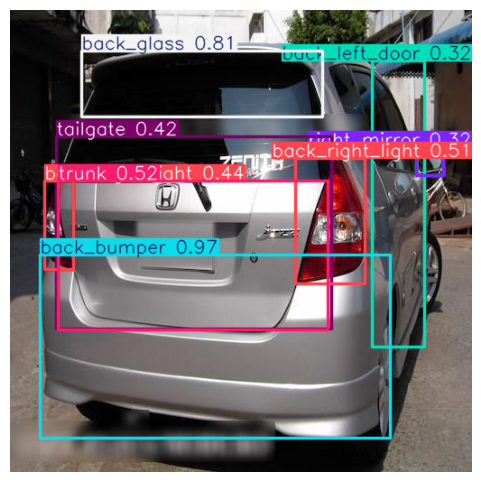

In [16]:
import random
import cv2
import matplotlib.pyplot as plt

test_images = list((YOLO_ROOT / "val" / "images").glob("*.jpg"))
sample_imgs = random.sample(test_images, 2)

results = model(sample_imgs)

for r in results:
    img = cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(6,6))
    plt.imshow(img)
    plt.axis("off")
    plt.show()

In [17]:
import numpy as np
from collections import defaultdict

iou_per_class = defaultdict(list)

for r in results:
    if r.boxes is None:
        continue

    for box in r.boxes:
        cls = int(box.cls.item())
        iou = box.iou.item() if hasattr(box, "iou") else 0
        iou_per_class[cls].append(iou)

avg_iou = {
    class_names[k]: np.mean(v) if len(v) > 0 else 0
    for k, v in iou_per_class.items()
}

hardest_class = min(avg_iou, key=avg_iou.get)

avg_iou, hardest_class


({'front_glass': np.float64(0.0),
  'hood': np.float64(0.0),
  'front_bumper': np.float64(0.0),
  'wheel': np.float64(0.0),
  'front_left_light': np.float64(0.0),
  'front_right_light': np.float64(0.0),
  'back_left_door': np.float64(0.0),
  'back_bumper': np.float64(0.0),
  'back_glass': np.float64(0.0),
  'trunk': np.float64(0.0),
  'back_right_light': np.float64(0.0),
  'tailgate': np.float64(0.0),
  'back_left_light': np.float64(0.0),
  'right_mirror': np.float64(0.0),
  'left_mirror': np.float64(0.0)},
 'front_glass')